In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.metrics import (confusion_matrix,classification_report,accuracy_score, precision_score,recall_score, f1_score,roc_auc_score, RocCurveDisplay)

import warnings
warnings.filterwarnings('ignore')

In [18]:
df=pd.read_csv("Invistico_Airline.csv")
df.head()

,satisfaction,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Seat comfort,Departure/Arrival time convenient,Food and drink,...,Online support,Ease of Online booking,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Online boarding,Departure Delay in Minutes,Arrival Delay in Minutes
0,satisfied,Female,Loyal Customer,65,Personal Travel,Eco,265,0,0,0,...,2,3,3,0,3,5,3,2,0,0.0
1,satisfied,Male,Loyal Customer,47,Personal Travel,Business,2464,0,0,0,...,2,3,4,4,4,2,3,2,310,305.0
2,satisfied,Female,Loyal Customer,15,Personal Travel,Eco,2138,0,0,0,...,2,2,3,3,4,4,4,2,0,0.0
3,satisfied,Female,Loyal Customer,60,Personal Travel,Eco,623,0,0,0,...,3,1,1,0,1,4,1,3,0,0.0
4,satisfied,Female,Loyal Customer,70,Personal Travel,Eco,354,0,0,0,...,4,2,2,0,2,4,2,5,0,0.0


In [35]:
print("shape:",df.shape)


shape: (129880, 24)


In [38]:
print("\nColumn Names:")
print(df.columns)


Column Names:
Index(['satisfaction', 'Gender', 'Customer Type', 'Age', 'Type of Travel',
       'Class', 'Flight Distance', 'Seat comfort',
       'Departure/Arrival time convenient', 'Food and drink', 'Gate location',
       'Inflight wifi service', 'Inflight entertainment', 'Online support',
       'Ease of Online booking', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness', 'Online boarding',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction_flag'],
      dtype='str')


In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   satisfaction                       129880 non-null  str    
 1   Gender                             129880 non-null  str    
 2   Customer Type                      129880 non-null  str    
 3   Age                                129880 non-null  int64  
 4   Type of Travel                     129880 non-null  str    
 5   Class                              129880 non-null  str    
 6   Flight Distance                    129880 non-null  int64  
 7   Seat comfort                       129880 non-null  int64  
 8   Departure/Arrival time convenient  129880 non-null  int64  
 9   Food and drink                     129880 non-null  int64  
 10  Gate location                      129880 non-null  int64  
 11  Inflight wifi service              129880 non-null

In [40]:

print(df.describe())

                 Age  Flight Distance   Seat comfort  \
count  129880.000000    129880.000000  129880.000000   
mean       39.427957      1981.409055       2.838597   
std        15.119360      1027.115606       1.392983   
min         7.000000        50.000000       0.000000   
25%        27.000000      1359.000000       2.000000   
50%        40.000000      1925.000000       3.000000   
75%        51.000000      2544.000000       4.000000   
max        85.000000      6951.000000       5.000000   

       Departure/Arrival time convenient  Food and drink  Gate location  \
count                      129880.000000   129880.000000  129880.000000   
mean                            2.990645        2.851994       2.990422   
std                             1.527224        1.443729       1.305970   
min                             0.000000        0.000000       0.000000   
25%                             2.000000        2.000000       2.000000   
50%                             3.000000     

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.isnull().sum()


satisfaction                           0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Seat comfort                           0
Departure/Arrival time convenient      0
Food and drink                         0
Gate location                          0
Inflight wifi service                  0
Inflight entertainment                 0
Online support                         0
Ease of Online booking                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Online boarding                        0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
dtype: int64

In [61]:
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].median())
print(df.isnull().sum())

satisfaction                         0
Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Seat comfort                         0
Departure/Arrival time convenient    0
Food and drink                       0
Gate location                        0
Inflight wifi service                0
Inflight entertainment               0
Online support                       0
Ease of Online booking               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Online boarding                      0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction_flag                    0
dtype: int64


### Target Distribution


satisfaction
satisfied       71087
dissatisfied    58793
Name: count, dtype: int64


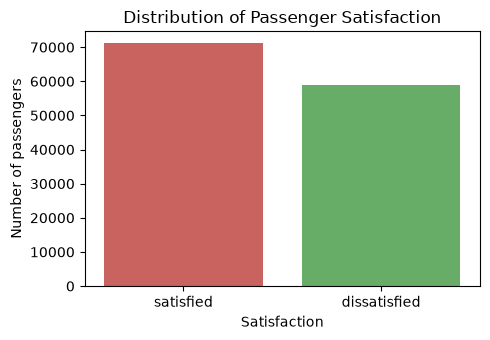

In [42]:
print(df['satisfaction'].value_counts())
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="satisfaction", hue="satisfaction", palette=["#d9534f", "#5cb85c"], legend=False, ax=ax)
ax.set_title("Distribution of Passenger Satisfaction")
ax.set_xlabel("Satisfaction")
ax.set_ylabel("Number of passengers")
plt.tight_layout()
plt.show()

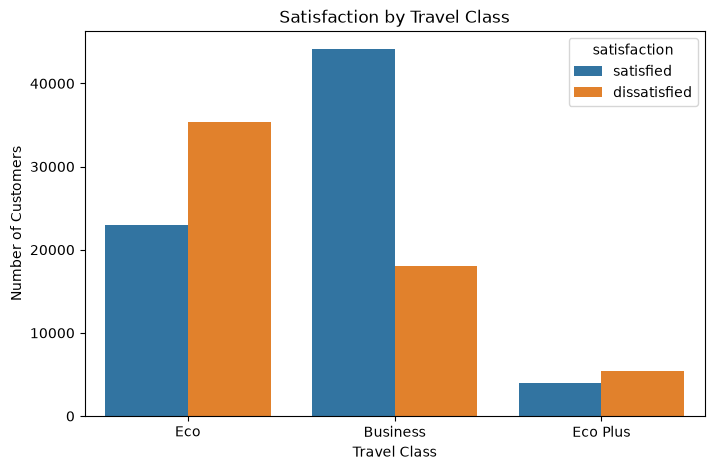

In [43]:
plt.figure(figsize=(8, 5))
sns.countplot( data=df,x='Class',hue='satisfaction')
plt.title("Satisfaction by Travel Class")
plt.xlabel("Travel Class")
plt.ylabel("Number of Customers")
plt.show()

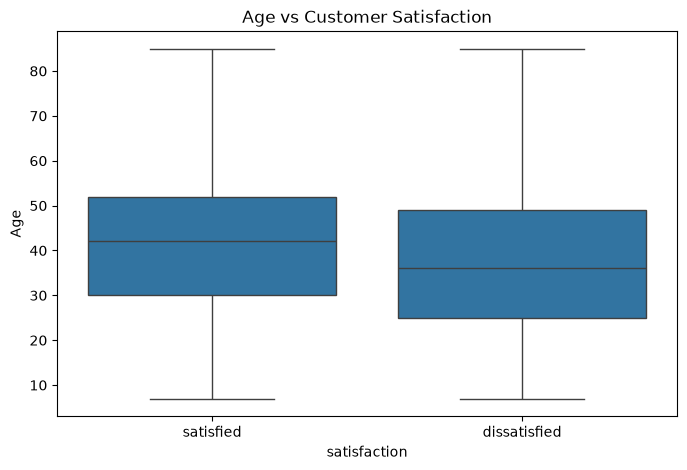

In [44]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='satisfaction', y='Age')
plt.title("Age vs Customer Satisfaction")
plt.show()

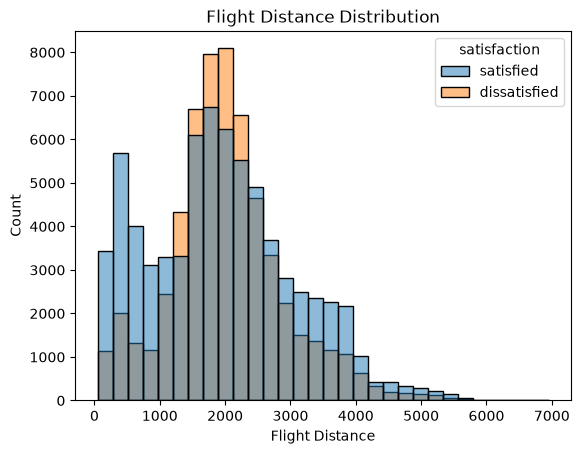

In [104]:
sns.histplot(data=df, x='Flight Distance', hue='satisfaction', bins=30)
plt.title('Flight Distance Distribution')
plt.show()

In [91]:
# target variable
y = df['satisfaction']
# input features
X = df.drop(['satisfaction', 'satisfaction_flag','Gender'], axis=1)
print("Input Features:", X.shape)
print("Target Variable:", y.shape)

Input Features: (129880, 21)
Target Variable: (129880,)


In [108]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
print(label_encoder.classes_)

[0 1]


In [110]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,random_state=42, stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (103904, 22)
Testing data: (25976, 22)


In [111]:
cat_cols = X_train.select_dtypes(include='object').columns

encoder = OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False)

X_train_encoded = encoder.fit_transform(X_train[cat_cols])
X_test_encoded = encoder.transform(X_test[cat_cols])

train_df = pd.DataFrame(X_train_encoded,columns=encoder.get_feature_names_out(cat_cols),index=X_train.index)

test_df = pd.DataFrame( X_test_encoded,columns=encoder.get_feature_names_out(cat_cols), index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

X_train = pd.concat([X_train, train_df], axis=1)
X_test = pd.concat([X_test, test_df], axis=1)



In [112]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)
print(label_encoder.classes_)

[0 1]


In [122]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [123]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [124]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
result = pd.DataFrame({'Actual': y_test,'Predicted': y_pred})
result.head(10)

,Actual,Predicted
0,1,1
1,1,1
2,0,0
3,1,1
4,0,0
5,0,0
6,1,1
7,0,0
8,1,0
9,1,0


In [134]:
print("Accuracy:", f"{accuracy_score(y_test, y_pred) * 100:.2f}%")
print("Precision:", f"{precision_score(y_test, y_pred) * 100:.2f}%")
print("Recall:", f"{recall_score(y_test, y_pred) * 100:.2f}%")
print("F1 Score:", f"{f1_score(y_test, y_pred) * 100:.2f}%")
print("ROC-AUC:", f"{roc_auc_score(y_test, y_prob) * 100:.2f}%")

Accuracy: 82.89%
Precision: 84.41%
Recall: 84.30%
F1 Score: 84.36%
ROC-AUC: 90.35%


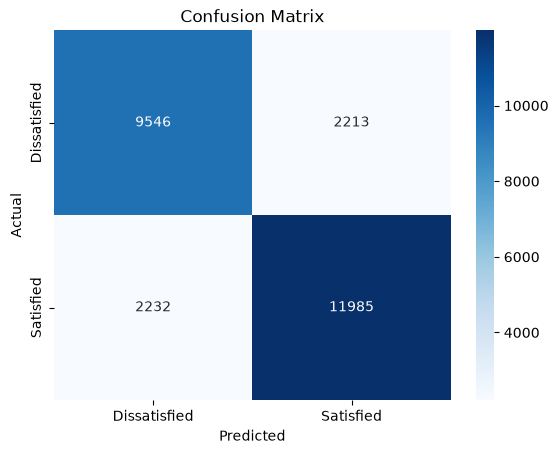

In [127]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Dissatisfied', 'Satisfied'], yticklabels=['Dissatisfied', 'Satisfied'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [128]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.81      0.81     11759
           1       0.84      0.84      0.84     14217

    accuracy                           0.83     25976
   macro avg       0.83      0.83      0.83     25976
weighted avg       0.83      0.83      0.83     25976



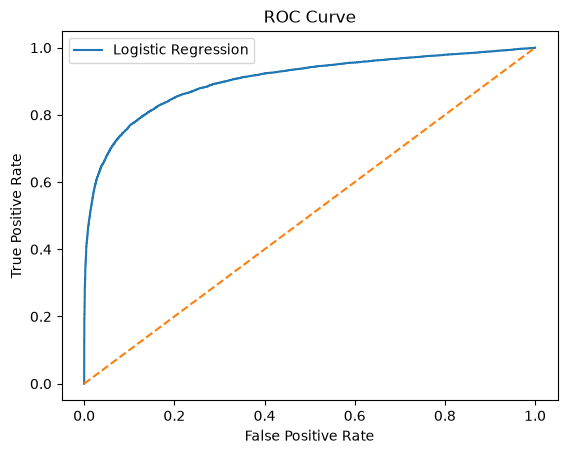

In [129]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

In [130]:
feature_names = list( X.drop(columns=cat_cols).columns) + list(encoder.get_feature_names_out(cat_cols))
importance = pd.DataFrame({'Feature': feature_names,'Coefficient': model.coef_[0]})

importance = importance.sort_values(by='Coefficient', ascending=False)

print(importance)

                              Feature  Coefficient
7              Inflight entertainment     0.972905
2                        Seat comfort     0.392582
10                   On-board service     0.387346
13                    Checkin service     0.355612
9              Ease of Online booking     0.334382
11                   Leg room service     0.308623
15                    Online boarding     0.181621
5                       Gate location     0.162930
8                      Online support     0.144692
12                   Baggage handling     0.109271
16         Departure Delay in Minutes     0.073041
14                        Cleanliness     0.064025
6               Inflight wifi service    -0.127214
0                                 Age    -0.132652
1                     Flight Distance    -0.181013
21                     Class_Eco Plus    -0.197960
17           Arrival Delay in Minutes    -0.261873
4                      Food and drink    -0.296070
3   Departure/Arrival time conv

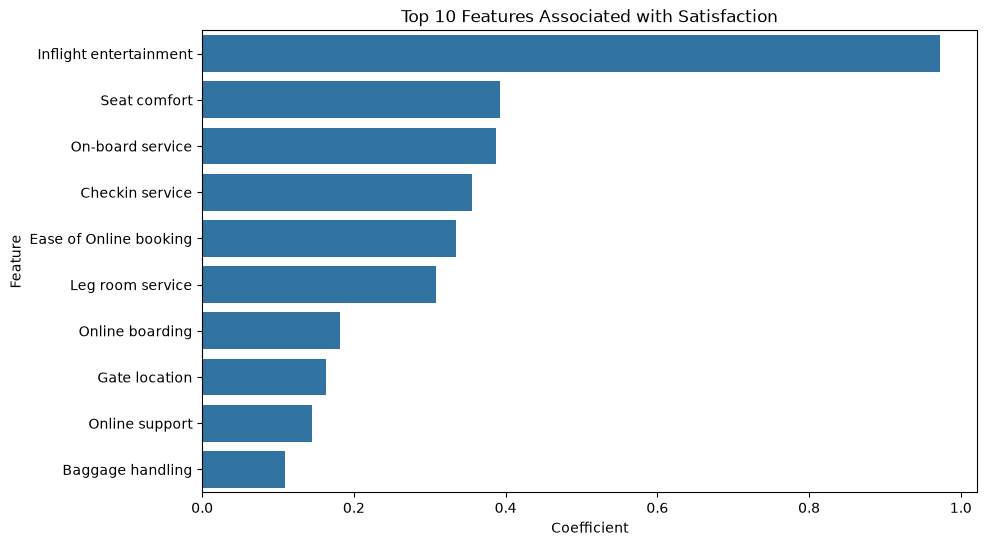

In [131]:
plt.figure(figsize=(10, 6))
sns.barplot(data=importance.head(10), x='Coefficient',y='Feature')

plt.title('Top 10 Features Associated with Satisfaction')
plt.show()

1. Important Features

The feature analysis shows that Inflight entertainment has the strongest positive association with customer satisfaction, with a coefficient of 0.973. Other important positive features include seat comfort, on-board service, check-in service and ease of online booking.

Some features, such as disloyal customer type, personal travel and economy class, have negative coefficients. This indicates that these factors are associated with a lower likelihood of customer satisfaction when other features are held constant.

Overall, the results suggest that the quality of in-flight services and the overall travel experience are important factors associated with passenger satisfaction.

2. Model Reliability

The Logistic Regression model achieved an accuracy of 83%, meaning it correctly classified approximately 83% of passengers in the test dataset.

The model achieved:

Precision: 84% for satisfied passengers.

Recall: 84% for satisfied passengers.

F1-score: 84% for satisfied passengers.

ROC-AUC: 90.35% for satisfied passengers.

These results indicate that the model performs reasonably well in identifying satisfied and dissatisfied passengers. However, it still makes some incorrect predictions.

3. Limitations of the Model

* Logistic Regression assumes a linear relationship between input features and the log-odds of the target, so it may not capture complex patterns.

* The model may not perform equally well on data from different airlines or future passengers.

* Customer satisfaction can depend on personal expectations and experiences that are difficult to measure.

* The model identifies associations between features and satisfaction but cannot establish cause-and-effect relationships.

* The dataset may not represent every type of airline passenger or travel experience.